# DX603 Final Project Milestone: Explore the Data Sets and Model Families

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**

### What We Will Do in This Milestone

This milestone is the first stage of your final machine learning project. You will have **three weeks** to explore real-world data, prepare it for modeling, and investigate several approaches to prediction. We will follow a simplified version of the machine learning workflow developed throughout the course:

1. **Explore the data:** Investigate two datasets, identify important characteristics and challenges, and select one for your project.
2. **Prepare the data:** Clean the selected dataset, handle missing values and categorical features, and create training, validation, and test sets without data leakage.
3. **Establish a baseline:** Train and evaluate a linear or logistic regression model as a starting point.
4. **Experiment with features:** Conduct two distinct feature-engineering experiments to investigate how changes in the predictors affect performance.
5. **Compare model families:** Compare a linear or logistic model, a tree ensemble, and a feedforward neural network, and investigate how one change in model complexity affects performance.

The goal is not necessarily to obtain the best possible prediction at this stage, but to **develop a sound experimental workflow and understand how different modeling choices affect performance**.

In the final stage of the project, you will have another three weeks to build on this work with additional experiments, improve and select your models using validation results, evaluate your final model on the test set, and submit both a completed code notebook and a written report.

### The Datasets

You will explore two datasets and then choose **one** to use for the remainder of your project.

| Dataset | Prediction task | Target | Primary validation metric |
|---|---|---|---|
| **Zillow** | Regression: predict assessed property value | `taxvaluedollarcnt` | **MAE** (lower is better) |
| **Hotel Booking Demand** | Binary classification: predict booking cancellation | `is_canceled` (1 = canceled) | **F1** for predicting canceled bookings (higher is better) |

**Zillow:** This is a subset of the housing dataset used in the 2017 Zillow Prize competition on Kaggle. Your goal is to predict the assessed tax value of a property from a large collection of property descriptors. The data contains missing values, potentially redundant or irrelevant features, and outliers that make accurate prediction challenging.

**Hotel Booking Demand:** This dataset contains information about hotel reservations, including booking characteristics, guest information, and reservation details. Your goal is to predict whether a reservation will be canceled. In addition to the usual challenges of preparing real-world data, you will need to consider classification metrics and whether features would actually be available when making a prediction.

Neither dataset is preferred, and you will not be graded on which one you choose. **After Problem 1, use the same dataset for Problems 2–5 and for your final project.**

### How to Complete This Notebook

- Run the provided setup cells first. Complete the computational tasks using Python code, adding working code cells as needed.
- Write your reflections in the designated **Python answer variables**, using triple-quoted strings, as in the weekly homeworks. Use the exact variable names specified.
- **Do not modify the Graded Answer cells**, and be sure to run them before submitting.
- Base your conclusions on **your own computed results**. Keep relevant code, plots, outputs, and reflections visible in your submitted notebook.
- Use `random_state=42` where possible, document your modeling choices, and do not delete the provided task instructions.
- **Do not evaluate your models on the test set in this milestone.** You will reserve that evaluation for the final submission.

**Total: 100 points.**

In [1]:

# General utilities
import os
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Data splitting
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
    PolynomialFeatures
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# TensorFlow / Keras setup
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPUs: []


## Setup and Dataset Loading

In Problem 1, you will explore two datasets before choosing one for the remainder of your project.

Run the setup cell below to load both datasets. If a dataset is already available locally, the code will use that copy. Otherwise, it will automatically download the dataset and save it for future use.

The original datasets will remain unchanged during Problem 1.

**Dataset Sources**

- **Zillow:** Course-provided housing dataset.
- **Hotel Booking Demand:** António, Almeida, and Nunes (2019). [Dataset on Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand).

In [2]:

# Download a dataset only if it is not already available locally

def load_dataset(url):
    filename = os.path.basename(urlparse(url).path)

    if not os.path.exists(filename):
        try:
            print(f"Downloading {filename}...")
            response = requests.get(url, timeout=120)
            response.raise_for_status()
            with open(filename, "wb") as f:
                f.write(response.content)
            print("File downloaded successfully.")
        except requests.exceptions.RequestException as e:
            raise RuntimeError(
                f"Error downloading {filename}: {e}"
            ) from e
    else:
        print(f"{filename} already exists. Skipping download.")

    return pd.read_csv(filename)


# Zillow dataset
zillow_url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/zillow_dataset.csv"
df_zillow = load_dataset(zillow_url)

# Hotel Booking Demand dataset
hotel_url = (
    "https://raw.githubusercontent.com/aaqibqadeer/"
    "Hotel-booking-demand/master/hotel_bookings.csv"
)
df_hotel = load_dataset(hotel_url)

print("\nDataset dimensions:")
print("Zillow:", df_zillow.shape)
print("Hotel Booking:", df_hotel.shape)


File downloaded successfully.
File downloaded successfully.

Dataset dimensions:
Zillow: (77613, 55)
Hotel Booking: (119390, 32)


## Problem 1 — Explore, Select, and Define a Prediction Task [15 points]

### Part A: Preliminary EDA of Both Datasets [10 points]

Before selecting a dataset for your project, conduct a brief exploratory analysis of **both** datasets, using the original dataframes `df_zillow` and `df_hotel`.

For each dataset:

**a. Dataset dimensions and types:** Report the number of observations, the number of predictors (excluding the target), and the number of columns currently stored as numerical and categorical. Remember that a column's data type does not necessarily reflect its meaning; for example, identifiers may be stored as integers.

**b. Target distribution:** Visualize the distribution of the target variable. For Zillow, include appropriate summary statistics for assessed property values. For Hotel Booking, report cancellation counts and percentages.

**c. Missing values:** Identify the five columns with the highest percentages of missing values (or all columns with missing values if fewer than five).

**d. Feature types:** Identify any high-cardinality categorical features or numeric-looking codes and identifiers that may require special handling during preprocessing.

**e. Data quality:** Describe one or two additional potential data-quality concerns you observe, explaining briefly why they might matter for modeling.

Keep this investigation focused. You do not need to plot every feature or perform any cleaning at this stage. The goal is to **understand the characteristics and challenges of each dataset before choosing one for your project.**


Zillow
Observations                            77613
Predictors (excluding target)              54
Numerical columns (including target)       50
Categorical columns                         5
Other dtype columns                         0

Columns with the highest missing percentages:
buildingclasstypeid     99.980673
finishedsquarefeet13    99.945885
storytypeid             99.935578
basementsqft            99.935578
yardbuildingsqft26      99.909809

High-cardinality categorical predictors (>20 unique values):
propertyzoningdesc           1907
propertycountylandusecode      75

Codes and identifiers requiring semantic review:
                          Stored dtype  Unique nonmissing values  Missing (%)
parcelid                         int64                     77414     0.000000
propertylandusetypeid          float64                        13     0.043807
propertycountylandusecode          str                        75     0.043807
fips                           float64               

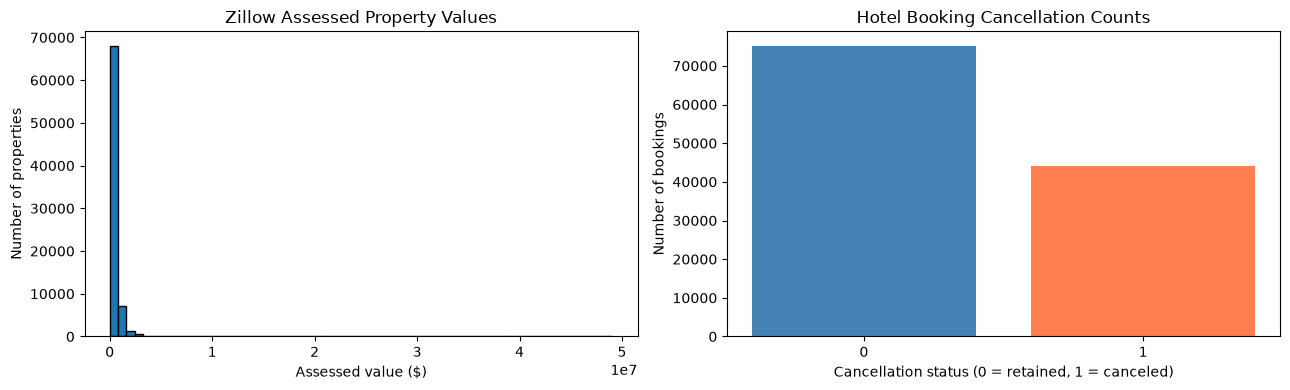


Additional Hotel Booking quality checks:
Negative average daily rates: 1
Bookings with zero total guests: 180

Potential Zillow valuation-related leakage: []
Potential Hotel post-outcome leakage: ['reservation_status', 'reservation_status_date']


In [3]:
# Your code here; add as many cells as you wish
def explore_dataset(df, name, target, code_candidates):
    """Report dataset structure, missingness, feature types, and duplicates."""
    # Count columns by stored dtype, including the target.
    numeric = df.select_dtypes(include="number").columns
    categorical = df.select_dtypes(
        include=["object", "category", "string", "bool"]
    ).columns

    print(f"\n{'=' * 60}\n{name}")
    print(pd.Series({
        "Observations": len(df),
        "Predictors (excluding target)": df.shape[1] - 1,
        "Numerical columns (including target)": len(numeric),
        "Categorical columns": len(categorical),
        "Other dtype columns": df.shape[1] - len(numeric) - len(categorical),
    }).to_string())

    # Show the five largest nonzero missing-value percentages.
    missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)
    print("\nColumns with the highest missing percentages:")
    print(missing_pct[missing_pct > 0].head(5).rename("Missing (%)").to_string())

    # Flag high-cardinality categorical predictors; 20 is an EDA heuristic.
    cardinality = df[
        [column for column in categorical if column != target]
    ].nunique().sort_values(ascending=False)
    print("\nHigh-cardinality categorical predictors (>20 unique values):")
    print(cardinality[cardinality > 20].rename("Unique values").to_string())

    # Inspect known codes and identifiers 
    codes = [column for column in code_candidates if column in df.columns]
    code_summary = pd.DataFrame({
        "Stored dtype": df[codes].dtypes.astype(str),
        "Unique nonmissing values": df[codes].nunique(),
        "Missing (%)": df[codes].isna().mean().mul(100),
    })
    print("\nCodes and identifiers requiring semantic review:")
    print(code_summary.to_string())

  
    print(f"\nExact duplicate rows beyond the first: {df.duplicated().sum():,}")
    print(f"Missing target values: {df[target].isna().sum():,}")


# Examine both datasets without cleaning or changing their original values.
explore_dataset(
    df_zillow,
    "Zillow",
    "taxvaluedollarcnt",
    [
        "parcelid", "propertylandusetypeid", "propertycountylandusecode",
        "fips", "regionidzip", "regionidcity", "regionidcounty",
        "regionidneighborhood", "censustractandblock", "rawcensustractandblock",
        "buildingqualitytypeid", "airconditioningtypeid", "heatingorsystemtypeid",
    ],
)

explore_dataset(
    df_hotel,
    "Hotel Booking",
    "is_canceled",
    ["agent", "company", "arrival_date_year", "arrival_date_week_number"],
)

# Summarize assessed property values, including the upper tail.
values = df_zillow["taxvaluedollarcnt"]
print("\nZillow assessed property value summary:")
print(values.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_string())
print(f"Nonpositive assessed values: {(values <= 0).sum():,}")
print(f"Target skewness: {values.skew():.2f}")

# Report cancellation counts and percentages among nonmissing targets.
cancellations = df_hotel["is_canceled"].value_counts().sort_index()
cancellation_summary = pd.DataFrame({
    "Count": cancellations,
    "Percentage (%)": cancellations / cancellations.sum() * 100,
})
print("\nHotel cancellation distribution (0 = retained, 1 = canceled):")
print(cancellation_summary.to_string())

# Visualize both target distributions on separate axes.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(values.dropna(), bins=60, edgecolor="black")
axes[0].set(
    title="Zillow Assessed Property Values",
    xlabel="Assessed value ($)",
    ylabel="Number of properties",
)
axes[0].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))

axes[1].bar(
    cancellations.index.astype(str),
    cancellations.values,
    color=["steelblue", "coral"],
)
axes[1].set(
    title="Hotel Booking Cancellation Counts",
    xlabel="Cancellation status (0 = retained, 1 = canceled)",
    ylabel="Number of bookings",
)
plt.tight_layout()
plt.show()

# Quantify potential hotel data-quality concerns without removing any rows.
print("\nAdditional Hotel Booking quality checks:")
if "adr" in df_hotel.columns:
    print(f"Negative average daily rates: {(df_hotel['adr'] < 0).sum():,}")

guest_columns = ["adults", "children", "babies"]
if all(column in df_hotel.columns for column in guest_columns):
    # Require all three counts to be present before flagging zero guests.
    guests = df_hotel[guest_columns].sum(axis=1, min_count=3)
    print(f"Bookings with zero total guests: {(guests == 0).sum():,}")

# Flag possible prediction-time leakage for later investigation.
zillow_leakage = [
    column for column in [
        "structuretaxvaluedollarcnt", "landtaxvaluedollarcnt", "taxamount"
    ] if column in df_zillow.columns
]
hotel_leakage = [
    column for column in ["reservation_status", "reservation_status_date"]
    if column in df_hotel.columns
]
print("\nPotential Zillow valuation-related leakage:", zillow_leakage)
print("Potential Hotel post-outcome leakage:", hotel_leakage)

### Reflection 1.A — Preliminary Data Exploration

Compare the two datasets based on your preliminary EDA. 

> What did you learn about their target distributions, missing values, feature types, and potential data-quality problems?

Refer to specific results from your tables and plots. Identify the most important modeling challenges you anticipate for each dataset, and briefly explain why they might affect predictive performance.

Write **a coherent response of approximately 100–200 words** in `a1a`.

In [4]:
# Compute specific results 
z_values = df_zillow["taxvaluedollarcnt"]
z_missing = df_zillow.isna().mean().mul(100).sort_values(ascending=False)
h_missing = df_hotel.isna().mean().mul(100).sort_values(ascending=False)
cancel_count = df_hotel["is_canceled"].eq(1).sum()
cancel_pct = df_hotel["is_canceled"].dropna().eq(1).mean() * 100


In [5]:
# Your answer here, NOT in the next cell

a1a = f"""
The two datasets present different modeling challenges. Zillow's assessed
property values have a mean of ${z_values.mean():,.0f}, a median of
${z_values.median():,.0f}, and a 99th percentile of
${z_values.quantile(0.99):,.0f}. Alongside the histogram, these numbers
help show how much the most expensive properties differ from typical
ones. These properties could lead to large prediction errors.
Missing data is another concern: {z_missing.index[0]} is
{z_missing.iloc[0]:.1f}% missing. Parcel IDs and geographic codes also
need careful handling because their numerical values are not ordinary
measurements.

For Hotel Booking, {cancel_count:,} reservations were canceled
({cancel_pct:.1f}% of nonmissing outcomes). This class distribution
makes precision, recall, and F1 important when evaluating predictions.
The column {h_missing.index[0]} is {h_missing.iloc[0]:.1f}% missing,
while country categories and agent/company IDs require suitable encoding.

Hotel also has {df_hotel.duplicated().sum():,} duplicate rows beyond the
first. These need investigation rather than automatic removal, since
different bookings can share identical details. Finally, both datasets
raise leakage concerns: Zillow's valuation components and hotel's
reservation-status fields could reveal the outcome, making validation
results look better than realistic predictions would be.
"""

In [6]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
The two datasets present different modeling challenges. Zillow's assessed
property values have a mean of $490,151, a median of
$358,878, and a 99th percentile of
$2,758,771. Alongside the histogram, these numbers
help show how much the most expensive properties differ from typical
ones. These properties could lead to large prediction errors.
Missing data is another concern: buildingclasstypeid is
100.0% missing. Parcel IDs and geographic codes also
need careful handling because their numerical values are not ordinary
measurements.

For Hotel Booking, 44,224 reservations were canceled
(37.0% of nonmissing outcomes). This class distribution
makes precision, recall, and F1 important when evaluating predictions.
The column company is 94.3% missing,
while country categories and agent/company IDs require suitable encoding.

Hotel also has 31,994 duplicate rows beyond the
first. These need investigation rather than automatic removal, since
different bookings can share identical details

### Part B: Select One Dataset [5 points]

Choose **Zillow** or **Hotel Booking** as the dataset for your final project.

Base your decision on your preliminary EDA, your interest in the prediction task, and the modeling challenges you identified.

Record your selection in `a1_dataset`, using exactly `"Zillow"` or `"Hotel Booking"`.

**Your choice itself is not graded.** You will use this dataset for the remainder of the milestone and the final project.

In [7]:
# Select your dataset: "Zillow" or "Hotel Booking"

a1_dataset = "Hotel Booking"  # "Zillow" or "Hotel Booking"

In [8]:
# Dataset selection and setup
# DO NOT change this cell

assert a1_dataset in ("Zillow", "Hotel Booking"), \
    "Choose exactly 'Zillow' or 'Hotel Booking'."

if a1_dataset == "Zillow":
    selected_raw = df_zillow.copy()
    target = "taxvaluedollarcnt"
    task = "regression"
else:
    selected_raw = df_hotel.copy()
    target = "is_canceled"
    task = "classification"

print("Selected dataset:", a1_dataset, "(stored in selected_raw)")
print("Prediction task:", task)
print("Target:", target)
print("Dataset shape:", selected_raw.shape)

Selected dataset: Hotel Booking (stored in selected_raw)
Prediction task: classification
Target: is_canceled
Dataset shape: (119390, 32)


### Reflection 1.B — Dataset Selection

Explain why you selected this dataset. What attracts you to its prediction task?

> 1. Identify **two specific modeling challenges** revealed by your preliminary EDA,
> 2. Explain how they might affect your approach, and
> 3. Identify **one interesting challenge** in the dataset you did not choose.

Support your discussion with observations from Problem 1.A.

Write **a coherent response of approximately 100–150 words** in `a1b`.

In [9]:
# Your answer here, NOT in the next cell

a1b = f"""
I selected Hotel Booking because predicting cancellations has a clear
practical use: helping hotels plan room availability and reduce lost
revenue. I am interested in seeing how booking details can distinguish
reservations that are canceled from those that are kept.

One challenge from my EDA is missing information:
{h_missing.index[0]} is {h_missing.iloc[0]:.1f}% missing. I will consider
whether to retain this feature and how to represent missing categories,
rather than discard otherwise useful bookings. A second challenge is
leakage from reservation_status and reservation_status_date. These fields
describe the outcome and would not be known when a reservation is made,
so I will exclude them to keep evaluation realistic.

Zillow's wide range of assessed values is also interesting. Its 99th
percentile is ${z_values.quantile(0.99):,.0f}, highlighting expensive
properties that could contribute large prediction errors and make
accurate valuation difficult.
"""

In [10]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
I selected Hotel Booking because predicting cancellations has a clear
practical use: helping hotels plan room availability and reduce lost
revenue. I am interested in seeing how booking details can distinguish
reservations that are canceled from those that are kept.

One challenge from my EDA is missing information:
company is 94.3% missing. I will consider
whether to retain this feature and how to represent missing categories,
rather than discard otherwise useful bookings. A second challenge is
leakage from reservation_status and reservation_status_date. These fields
describe the outcome and would not be known when a reservation is made,
so I will exclude them to keep evaluation realistic.

Zillow's wide range of assessed values is also interesting. Its 99th
percentile is $2,758,771, highlighting expensive
properties that could contribute large prediction errors and make
accurate valuation difficult.



## Problem 2 — Clean and Prepare Your Selected Dataset [20 points]

In this problem, you will prepare **only the dataset you selected in Problem 1** for modeling. Your goal is to construct a reproducible preprocessing workflow that can be reused throughout the milestone and final project.

Make cleaning decisions based on your preliminary EDA. In particular, consider **which predictors would actually be available at prediction time**. Any preprocessing steps that learn from the data (such as imputation, scaling, and encoding) must be fitted on **training data only**.

**Do not train models or evaluate test-set performance in this problem.**

### Part A: Examine the Data and Plan Cleaning [5 points]

Starting with `selected_raw` from Problem 1:

1. Report the number of rows and columns, the number of missing target values, and the number of exact duplicate rows. Do not assume that every duplicate is an error.
2. Identify important predictors with missing values, numeric-looking categorical codes or identifiers, and any other features requiring special attention.
3. Identify **at least two specific cleaning decisions**, including **one concerning whether a feature would be available at prediction time**. For Hotel Booking, consider what is known when a reservation is made; for Zillow, consider whether a feature directly reveals or postdates the assessed value.

Present your findings using appropriate tables or summary statistics. Use additional code cells as needed to investigate potential problems. **Do not perform any cleaning or fit any preprocessing transformations yet.**

In [11]:
# Your code here; add additional cells as needed
# Problem 2.A: Investigation only; no cleaning or preprocessing.
assert a1_dataset == "Hotel Booking"

print("Dataset summary:")
display(pd.Series({
    "Rows": selected_raw.shape[0],
    "Columns": selected_raw.shape[1],
    "Missing target values": selected_raw[target].isna().sum(),
    "Exact duplicate rows beyond the first": selected_raw.duplicated().sum(),
}).to_frame("Count"))

# Missing predictors: report counts, percentages, and stored types.
missing_counts = selected_raw.isna().sum()
missing_features = [
    col for col in selected_raw.columns
    if col != target and missing_counts[col] > 0
]

missing_summary = pd.DataFrame({
    "Missing count": missing_counts[missing_features],
    "Missing (%)": selected_raw[missing_features].isna().mean() * 100,
    "Stored dtype": selected_raw[missing_features].dtypes.astype(str),
}).sort_values("Missing (%)", ascending=False)

print("\nPredictors with missing values:")
display(missing_summary.round(2))

# Review feature meaning rather than relying only on dtype.
attention_notes = {
    "agent": "Agent identifier: categorical, not a continuous measurement.",
    "company": "Company identifier: categorical; review substantial missingness.",
    "country": "Categorical feature; many countries may need rare-category grouping.",
    "arrival_date_month": "Month names: consider categorical or seasonal representation.",
    "reservation_status": "Final booking outcome: unavailable when booking is made.",
    "reservation_status_date": "Date of final status: unavailable when booking is made.",
    "assigned_room_type": "May reflect later room allocation; review availability.",
    "booking_changes": "May include changes made after the initial reservation.",
    "days_in_waiting_list": "May reflect waiting time accumulated after booking.",
}

attention_columns = [
    col for col in attention_notes if col in selected_raw.columns
]
attention_summary = pd.DataFrame({
    "Stored dtype": selected_raw[attention_columns].dtypes.astype(str),
    "Unique nonmissing values": selected_raw[attention_columns].nunique(),
    "Reason for attention": [attention_notes[col] for col in attention_columns],
})

print("\nFeatures requiring special handling:")
display(attention_summary)

# Quantify additional concerns without removing or modifying rows.
guest_total = selected_raw[["adults", "children", "babies"]].sum(
    axis=1, min_count=3
)

quality_checks = pd.Series({
    "Bookings with zero total guests": guest_total.eq(0).sum(),
    "Bookings with negative daily rates": selected_raw["adr"].lt(0).sum(),
    "Rows belonging to exact-duplicate groups":
        selected_raw.duplicated(keep=False).sum(),
    "Unexpected nonmissing target values":
        (
            selected_raw[target].notna()
            & ~selected_raw[target].isin([0, 1])
        ).sum(),
})

print("\nAdditional data-quality checks:")
display(quality_checks.to_frame("Count"))

print("\nAverage daily rate summary:")
display(
    selected_raw["adr"]
    .describe(percentiles=[0.5, 0.95, 0.99])
    .to_frame("ADR")
)

# Record proposed decisions; do not implement them in this part.
cleaning_plan = pd.DataFrame([
    {
        "Feature / concern": "reservation_status, reservation_status_date",
        "Planned decision": "Exclude from predictors.",
        "Reason": "These describe the final outcome, causing prediction-time leakage.",
    },
    {
        "Feature / concern": "assigned_room_type, booking_changes, days_in_waiting_list",
        "Planned decision": "Conservatively exclude for prediction at initial booking.",
        "Reason": "The recorded values may contain information accumulated after booking.",
    },
    {
        "Feature / concern": "Missing predictor values",
        "Planned decision": "Retain bookings; handle missingness in the later pipeline.",
        "Reason": "Missing predictors do not make the target unusable; fit imputation on training only.",
    },
    {
        "Feature / concern": "agent, company, country",
        "Planned decision": "Treat IDs as categories; consider grouping rare categories.",
        "Reason": "Identifier magnitudes have no meaningful numerical ordering.",
    },
    {
        "Feature / concern": "Exact duplicates",
        "Planned decision": "Investigate before removal; assess cross-split overlap risk.",
        "Reason": "Identical details may represent separate bookings, but overlap can inflate validation scores.",
    },
    {
        "Feature / concern": "Zero guests and unusual daily rates",
        "Planned decision": "Investigate before deciding whether to remove or correct.",
        "Reason": "Unusual records are not automatically confirmed errors.",
    },
])

print("\nPlanned cleaning and feature-selection decisions:")
display(cleaning_plan)

Dataset summary:


,Count
Rows,119390
Columns,32
Missing target values,0
Exact duplicate rows beyond the first,31994



Predictors with missing values:


,Missing count,Missing (%),Stored dtype
company,112593,94.31,float64
agent,16340,13.69,float64
country,488,0.41,str
children,4,0.00,float64



Features requiring special handling:


,Stored dtype,Unique nonmissing values,Reason for attention
agent,float64,333,"Agent identifier: categorical, not a continuou..."
company,float64,352,Company identifier: categorical; review substa...
country,str,177,Categorical feature; many countries may need r...
arrival_date_month,str,12,Month names: consider categorical or seasonal ...
reservation_status,str,3,Final booking outcome: unavailable when bookin...
reservation_status_date,str,926,Date of final status: unavailable when booking...
assigned_room_type,str,12,May reflect later room allocation; review avai...
booking_changes,int64,21,May include changes made after the initial res...
days_in_waiting_list,int64,128,May reflect waiting time accumulated after boo...


... (2 outputs left out)


Average daily rate summary:


,ADR
count,119390.000000
mean,101.831122
std,50.535790
min,-6.380000
50%,94.575000
95%,193.500000
99%,252.000000
max,5400.000000



Planned cleaning and feature-selection decisions:


,Feature / concern,Planned decision,Reason
0,"reservation_status, reservation_status_date",Exclude from predictors.,"These describe the final outcome, causing pred..."
1,"assigned_room_type, booking_changes, days_in_w...",Conservatively exclude for prediction at initi...,The recorded values may contain information ac...
2,Missing predictor values,Retain bookings; handle missingness in the lat...,Missing predictors do not make the target unus...
3,"agent, company, country",Treat IDs as categories; consider grouping rar...,Identifier magnitudes have no meaningful numer...
4,Exact duplicates,Investigate before removal; assess cross-split...,Identical details may represent separate booki...
5,Zero guests and unusual daily rates,Investigate before deciding whether to remove ...,Unusual records are not automatically confirme...


### Reflection 2.A — Data Quality and Leakage

Based on your preliminary investigation of the selected dataset:

1. Explain **at least two specific cleaning or feature-selection decisions** you plan to make, and justify them using your findings.
2. For at least one decision, discuss whether the relevant information would actually be available at prediction time and how this affects your choice.
3. Explain how you plan to handle numeric-looking categorical codes or identifiers, if present.

Support your discussion with specific observations from your investigation.

Write **a coherent response of approximately 100–150 words** in `a2a`.

In [12]:
# Your answer here, NOT in the next cell

a2a = f"""
I plan to exclude reservation_status and reservation_status_date because
they describe the final booking outcome and would not be available when
a reservation is first made. Including them could leak cancellation
information and inflate validation performance. I will also conservatively
exclude assigned_room_type, booking_changes, and days_in_waiting_list,
since their recorded values may reflect events after the initial booking.

Missingness requires separate handling: company is
{selected_raw["company"].isna().mean() * 100:.1f}% missing, while agent is
{selected_raw["agent"].isna().mean() * 100:.1f}% missing. I plan to retain
these bookings and represent missing categorical values explicitly in
the later preprocessing pipeline. Agent and company numbers identify
categories rather than quantities, so I will encode them categorically,
considering training-based rare-category grouping.

Finally, the {selected_raw.duplicated().sum():,} exact duplicates beyond
the first require investigation rather than automatic deletion, because
distinct reservations can share identical details.
"""

In [13]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
I plan to exclude reservation_status and reservation_status_date because
they describe the final booking outcome and would not be available when
a reservation is first made. Including them could leak cancellation
information and inflate validation performance. I will also conservatively
exclude assigned_room_type, booking_changes, and days_in_waiting_list,
since their recorded values may reflect events after the initial booking.

Missingness requires separate handling: company is
94.3% missing, while agent is
13.7% missing. I plan to retain
these bookings and represent missing categorical values explicitly in
the later preprocessing pipeline. Agent and company numbers identify
categories rather than quantities, so I will encode them categorically,
considering training-based rare-category grouping.

Finally, the 31,994 exact duplicates beyond
the first require investigation rather than automatic deletion, because
distinct reservations can share identical details.



### Part B: Clean the Rows and Create Data Splits [4 points]

Using `selected_raw`, carry out only the row-level cleaning decisions justified by your investigation (for example, handling missing target values or confirmed duplicate errors). **Do not impute predictors, scale features, or encode categories before splitting.**

1. Separate the target (`target`) from the predictors. Remove predictors that should not be available at prediction time and any columns you decided to exclude. Keep track of the columns you remove and why.
2. Create **training (80%), validation (10%), and test (10%)** partitions, using `random_state=42`. For Hotel Booking, stratify by the target so the cancellation proportions remain similar across the partitions, where feasible.
3. Store the partitions in **`X_train`, `X_val`, `X_test`, `y_train`, `y_val`, and `y_test`**. Report their dimensions and, for Hotel Booking, the cancellation percentages in each partition.

Do not inspect the test set to make modeling decisions, and **do not evaluate any models on the test set**. Keep it untouched for the final submission.

In [14]:
# Your code here; add additional cells as needed

# Remove only rows without a usable target; leave selected_raw unchanged.
missing_target_rows = selected_raw[target].isna().sum()
selected_clean = selected_raw.dropna(subset=[target]).copy()

# Duplicates and unusual bookings are not confirmed errors, so retain them.
assert selected_clean[target].isin([0, 1]).all(), "Unexpected target values."

display(pd.Series({
    "Original rows": len(selected_raw),
    "Rows removed: missing target": missing_target_rows,
    "Remaining rows": len(selected_clean),
    "Exact duplicates retained beyond first":
        selected_clean.duplicated().sum(),
}).to_frame("Count"))

# Document feature exclusions for prediction at the initial reservation.
removed_columns = {
    "reservation_status": "Final outcome; directly reveals cancellation status.",
    "reservation_status_date": "Final-status date; unavailable at initial booking.",
    "assigned_room_type": "May reflect room allocation after initial booking.",
    "booking_changes": "May count changes occurring after initial booking.",
    "days_in_waiting_list": "May include waiting time accumulated after booking.",
}

display(
    pd.DataFrame(
        list(removed_columns.items()),
        columns=["Removed predictor", "Reason"],
    )
)

# Separate predictors and target; no imputation, scaling, or encoding.
X = selected_clean.drop(columns=[target, *removed_columns])
y = selected_clean[target].copy()

# First split: 80% training, 20% held out.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Divide held-out data equally: 10% validation, 10% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout,
    y_holdout,
    test_size=0.50,
    random_state=42,
    stratify=y_holdout,
)

# Only report required split metadata; no test-set modeling or diagnostics.
split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Predictor dimensions": features.shape,
        "Target dimensions": labels.shape,
        "Rows (%)": len(features) / len(selected_clean) * 100,
        "Canceled (%)": labels.eq(1).mean() * 100,
    }
    for name, features, labels in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test),
    ]
]).set_index("Partition")

display(split_summary.round(2))
print("No predictor preprocessing fitted and no models trained.")


,Count
Original rows,119390
Rows removed: missing target,0
Remaining rows,119390
Exact duplicates retained beyond first,31994


,Removed predictor,Reason
0,reservation_status,Final outcome; directly reveals cancellation s...
1,reservation_status_date,Final-status date; unavailable at initial book...
2,assigned_room_type,May reflect room allocation after initial book...
3,booking_changes,May count changes occurring after initial book...
4,days_in_waiting_list,May include waiting time accumulated after boo...


,Predictor dimensions,Target dimensions,Rows (%),Canceled (%)
Partition,,,,
Training,"(95512, 26)","(95512,)",80.0,37.04
Validation,"(11939, 26)","(11939,)",10.0,37.05
Test,"(11939, 26)","(11939,)",10.0,37.04


No predictor preprocessing fitted and no models trained.


### Reflection 2.B — Data Cleaning and Splitting

1. Describe the row-level cleaning and feature-removal decisions you made. Explain why these choices were appropriate for your selected prediction task.
2. Explain why the split must precede any preprocessing step that learns from the data, such as imputation or scaling.
3. For Hotel Booking, explain the role of stratification; for Zillow, comment on any important distributional concerns that remain after the split.

Refer to your results and split summary.

Write **a coherent response of approximately 100–150 words** in `a2b`.

In [15]:
# Your answer here, NOT in the next cell

a2b = f"""
The missing-target rule removed {missing_target_rows:,} rows. I retained
duplicates and unusual bookings because the investigation did not confirm
them as errors, although duplicate overlap could inflate validation scores.
I removed reservation_status and reservation_status_date because they
reveal the final outcome, plus assigned_room_type, booking_changes, and
days_in_waiting_list because they may contain information recorded after
initial booking.

The 80/10/10 split produced {len(X_train):,} training, {len(X_val):,}
validation, and {len(X_test):,} test rows, each with
{X_train.shape[1]} predictors. Splitting before learned preprocessing
prevents held-out information from influencing imputation values, scaling
statistics, or category definitions; these must be fitted on training
data only.

Stratification preserved similar cancellation proportions:
{split_summary.loc["Training", "Canceled (%)"]:.2f}%,
{split_summary.loc["Validation", "Canceled (%)"]:.2f}%, and
{split_summary.loc["Test", "Canceled (%)"]:.2f}%, respectively. This reduces
class-balance differences between partitions. The test set remains
reserved for final evaluation.
"""

In [16]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
The missing-target rule removed 0 rows. I retained
duplicates and unusual bookings because the investigation did not confirm
them as errors, although duplicate overlap could inflate validation scores.
I removed reservation_status and reservation_status_date because they
reveal the final outcome, plus assigned_room_type, booking_changes, and
days_in_waiting_list because they may contain information recorded after
initial booking.

The 80/10/10 split produced 95,512 training, 11,939
validation, and 11,939 test rows, each with
26 predictors. Splitting before learned preprocessing
prevents held-out information from influencing imputation values, scaling
statistics, or category definitions; these must be fitted on training
data only.

Stratification preserved similar cancellation proportions:
37.04%,
37.05%, and
37.04%, respectively. This reduces
class-balance differences between partitions. The test set remains
reserved for final evaluation.



### Part C: Build a Reusable Preprocessing Workflow [5 points]

Create a **scikit-learn preprocessing workflow** that can be used with each of the three model families in later problems.

1. Identify numerical and categorical predictor columns from `X_train`. Treat numeric-looking identifiers and categorical codes according to their meaning, not merely their stored data type.
2. Define appropriate preprocessing steps for each type of predictor:
   - **Numerical features:** Handle missing values using imputation and apply scaling where appropriate.
   - **Categorical features:** Handle missing values and convert categories into numerical representations:
     - For features with **few unique values**, use one-hot encoding.
     - For features with **many unique values**, consider grouping infrequent categories, frequency encoding, or dropping features that are unlikely to be useful for prediction (e.g., sample IDs, plot numbers, or other arbitrary identifiers).
     - For **ordinal features**, consider ordinal encoding when the categories have a meaningful order.
     - To reduce memory usage, consider sparse one-hot encoding (`sparse_output=True`) and avoid converting large sparse matrices to dense arrays.
3. Use scikit-learn's **`Pipeline`** to organize the numerical and categorical preprocessing steps, and **`ColumnTransformer`** to combine them into a single preprocessing workflow named `preprocessor`.

**Define but do not fit `preprocessor` in this part.** In Problem 3, it will be fitted as part of a model pipeline using only the training data. Do not fit preprocessing transformations on the validation or test sets, or transform all three partitions in advance.

In [17]:
# Your code here; add additional cells as needed
# Agent/company numbers are identifiers, not numerical measurements.
categorical_codes = [
    col for col in ["agent", "company"] if col in X_train.columns
]
categorical_cols = [
    col for col in X_train.columns
    if col in categorical_codes
    or not pd.api.types.is_numeric_dtype(X_train[col])
]
numerical_cols = [
    col for col in X_train.columns if col not in categorical_cols
]

# Use training data only to identify high-cardinality features.
cardinality = X_train[categorical_cols].nunique()
low_cardinality_cols = cardinality[cardinality <= 20].index.tolist()
high_cardinality_cols = cardinality[cardinality > 20].index.tolist()


display(pd.DataFrame({
    "Predictor": X_train.columns,
    "Treatment": [
        "Median imputation + standard scaling"
        if col in numerical_cols
        else (
            "Missing category + grouped sparse one-hot"
            if col in high_cardinality_cols
            else "Missing category + sparse one-hot"
        )
        for col in X_train.columns
    ],
}))


def categorical_to_strings(values):
    """Normalize category types while preserving missing values as np.nan."""
    frame = pd.DataFrame(values).copy()
    for col in frame.columns:
        frame[col] = frame[col].map(
            lambda value: np.nan if pd.isna(value) else str(value)
        )
    return frame.to_numpy(dtype=object)


numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
])


def make_categorical_pipeline(group_infrequent=False):
    return Pipeline([
        ("string_conversion", FunctionTransformer(
            categorical_to_strings,
            feature_names_out="one-to-one",
        )),
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="__MISSING__",
            keep_empty_features=True,
        )),
        ("encoder", OneHotEncoder(
            handle_unknown=(
                "infrequent_if_exist" if group_infrequent else "ignore"
            ),
            # Fixed policy: group categories below 1% of training observations.
            min_frequency=0.01 if group_infrequent else None,
            sparse_output=True,
            dtype=np.float32,
        )),
    ])


preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_cols),
        ("categorical_low", make_categorical_pipeline(), low_cardinality_cols),
        ("categorical_high", make_categorical_pipeline(True), high_cardinality_cols),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)

# Verify column coverage without fitting anything.
assigned_cols = numerical_cols + low_cardinality_cols + high_cardinality_cols
assert len(assigned_cols) == len(set(assigned_cols))
assert set(assigned_cols) == set(X_train.columns)
assert not hasattr(preprocessor, "transformers_")

print(f"Numerical predictors ({len(numerical_cols)}):", numerical_cols)
print("Low-cardinality categorical predictors:", low_cardinality_cols)
print("High-cardinality categorical predictors:", high_cardinality_cols)
print("preprocessor is defined and unfitted; validation/test data were not used.")


,Predictor,Treatment
0,hotel,Missing category + sparse one-hot
1,lead_time,Median imputation + standard scaling
2,arrival_date_year,Median imputation + standard scaling
3,arrival_date_month,Missing category + sparse one-hot
4,arrival_date_week_number,Median imputation + standard scaling
5,arrival_date_day_of_month,Median imputation + standard scaling
6,stays_in_weekend_nights,Median imputation + standard scaling
7,stays_in_week_nights,Median imputation + standard scaling
8,adults,Median imputation + standard scaling
9,children,Median imputation + standard scaling


Numerical predictors (15): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Low-cardinality categorical predictors: ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
High-cardinality categorical predictors: ['country', 'agent', 'company']
preprocessor is defined and unfitted; validation/test data were not used.


### Reflection 2.C — Preprocessing Choices

1. Justify your decisions for missing values, categorical encoding, and numerical scaling.
2. Explain how you handled any categorical codes, identifiers, or high-cardinality features.
3. Explain how your workflow avoids learning preprocessing parameters from validation or test data.

Connect your choices to characteristics of the selected dataset.

Write **a coherent response of approximately 100–150 words** in `a2c`.

In [18]:
# Your answer here, NOT in the next cell

a2c = """
I used median imputation for numerical features so bookings with missing
values, such as children, can still be included. The median is less
affected by extreme values than the mean. Scaling puts features like
lead_time and adr on comparable scales, which helps logistic regression
and neural networks, even though random forests do not need it.

For categorical features, I replace missing values with a missing label
rather than discard bookings. Agent and company numbers represent
identities, not quantities, so I treat them as categories. Features with
few categories use one-hot encoding; those with many, including country,
group categories appearing in fewer than 1% of training rows. Sparse
encoding keeps memory usage lower.

I used only X_train to organize the columns and left preprocessor
unfitted. Later, the model pipeline will learn imputation values, scaling
statistics, and category groupings from training data only, keeping
validation and test information out.

"""

In [19]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
I used median imputation for numerical features so bookings with missing
values, such as children, can still be included. The median is less
affected by extreme values than the mean. Scaling puts features like
lead_time and adr on comparable scales, which helps logistic regression
and neural networks, even though random forests do not need it.

For categorical features, I replace missing values with a missing label
rather than discard bookings. Agent and company numbers represent
identities, not quantities, so I treat them as categories. Features with
few categories use one-hot encoding; those with many, including country,
group categories appearing in fewer than 1% of training rows. Sparse
encoding keeps memory usage lower.

I used only X_train to organize the columns and left preprocessor
unfitted. Later, the model pipeline will learn imputation values, scaling
statistics, and category groupings from training data only, keeping
validation and test information out.




### Part D: Verify the Splits and Preprocessing Design [4 points]

Before modeling, verify that the outputs of Parts B and C are consistent and ready for use in the baseline model.

1. Confirm that the training, validation, and test partitions have the same predictor columns in the same order, and that each feature matrix has the corresponding number of target values.
2. Check that the target values are appropriate for your prediction task and that the predictors do not contain the target or any known sources of prediction-time leakage.
3. Verify that `preprocessor` contains the intended numerical and categorical transformations and references columns that exist in `X_train`. **Do not fit the preprocessor yet.**
4. Summarize the checks performed and identify any problems you found and corrected.

Use clear print statements or a small results table. Avoid displaying large data matrices.

In [20]:
# Your code here; add additional cells as needed
checks = []

def record_check(description, passed):
    checks.append({"Check": description, "Passed": bool(passed)})

excluded_predictors = {target, *removed_columns}

for name, features, labels in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    record_check(
        f"{name}: identical predictor columns and order",
        features.columns.equals(X_train.columns),
    )
    record_check(f"{name}: matching row counts", len(features) == len(labels))
    record_check(
        f"{name}: matching feature/target indices",
        features.index.equals(labels.index),
    )
    record_check(
        f"{name}: nonmissing binary targets",
        labels.notna().all() and labels.isin([0, 1]).all(),
    )
    record_check(
        f"{name}: target and excluded leakage fields absent",
        excluded_predictors.isdisjoint(features.columns),
    )

record_check("Predictor column names are unique", X_train.columns.is_unique)
record_check(
    "Classification task and cancellation target",
    task == "classification" and target == "is_canceled",
)
record_check(
    "Preprocessor remains unfitted",
    not hasattr(preprocessor, "transformers_"),
)

# Inspect configured transformations, not fitted transformations.
configured = {
    name: (pipeline, columns)
    for name, pipeline, columns in preprocessor.transformers
}
expected_columns = {
    "numerical": numerical_cols,
    "categorical_low": low_cardinality_cols,
    "categorical_high": high_cardinality_cols,
}

record_check(
    "Intended preprocessing branches exist",
    set(configured) == set(expected_columns),
)

referenced_columns = []
for name, (pipeline, columns) in configured.items():
    referenced_columns.extend(columns)
    record_check(
        f"{name}: intended column assignment",
        list(columns) == expected_columns.get(name),
    )

record_check(
    "All referenced columns exist in training data",
    set(referenced_columns).issubset(X_train.columns),
)
record_check(
    "Every predictor is assigned exactly once",
    len(referenced_columns) == len(set(referenced_columns))
    and set(referenced_columns) == set(X_train.columns),
)
record_check(
    "Agent/company IDs receive categorical treatment",
    set(categorical_codes).issubset(
        set(low_cardinality_cols + high_cardinality_cols)
    ),
)

if "numerical" in configured:
    steps = configured["numerical"][0].named_steps
    record_check(
        "Numerical: median imputation and standard scaling",
        isinstance(steps.get("imputer"), SimpleImputer)
        and steps["imputer"].strategy == "median"
        and isinstance(steps.get("scaler"), StandardScaler),
    )

for name, frequency, unknown_policy in [
    ("categorical_low", None, "ignore"),
    ("categorical_high", 0.01, "infrequent_if_exist"),
]:
    if name not in configured:
        continue
    steps = configured[name][0].named_steps
    imputer = steps.get("imputer")
    encoder = steps.get("encoder")
    record_check(
        f"{name}: string conversion and missing-category imputation",
        isinstance(steps.get("string_conversion"), FunctionTransformer)
        and steps["string_conversion"].func is categorical_to_strings
        and isinstance(imputer, SimpleImputer)
        and imputer.strategy == "constant"
        and imputer.fill_value == "__MISSING__",
    )
    record_check(
        f"{name}: intended sparse one-hot encoding",
        isinstance(encoder, OneHotEncoder)
        and encoder.sparse_output
        and encoder.min_frequency == frequency
        and encoder.handle_unknown == unknown_policy,
    )

verification_results = pd.DataFrame(checks)
display(verification_results)

failed_checks = verification_results.loc[
    ~verification_results["Passed"], "Check"
].tolist()

if failed_checks:
    print("Problems found; no automatic corrections were made:")
    for problem in failed_checks:
        print(f"- {problem}")
    raise AssertionError("Correct the failed checks before modeling.")
else:
    print("All checks passed. No corrections were needed.")
    print("No preprocessing was fitted and no model was trained.")
    print("These checks do not rule out duplicate overlap between splits.")

,Check,Passed
0,Training: identical predictor columns and order,True
1,Training: matching row counts,True
2,Training: matching feature/target indices,True
3,Training: nonmissing binary targets,True
4,Training: target and excluded leakage fields a...,True
5,Validation: identical predictor columns and order,True
6,Validation: matching row counts,True
7,Validation: matching feature/target indices,True
8,Validation: nonmissing binary targets,True
9,Validation: target and excluded leakage fields...,True


All checks passed. No corrections were needed.
No preprocessing was fitted and no model was trained.
These checks do not rule out duplicate overlap between splits.


### Reflection 2.D — Verifying Data Preparation

1. What evidence shows that the data splits and feature columns are ready for modeling?
2. Did the checks reveal any problems? If so, explain what you changed; if not, identify one potential preprocessing failure your checks were designed to catch.
3. Explain why this kind of verification matters before comparing different models.

Write **a coherent response of approximately 75–125 words** in `a2d`.

In [21]:
# Your answer here, NOT in the next cell

a2d = """
The checks showed that the training, validation, and test sets have the
same predictor columns in the same order, and each row matches its
target value. The targets are nonmissing zeros and ones, and the excluded
leakage fields are not included. I also confirmed that the preprocessor
uses the intended transformations, covers every predictor once, and
remains unfitted.

No issues were found, so no corrections were needed. One potential
problem these checks could catch is referencing a column that was removed
during cleaning. This verification helps make model comparisons fair:
differences in results should come from the models, not inconsistent
inputs or preparation mistakes. Duplicate overlap still needs separate
investigation.
"""

In [22]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
The checks showed that the training, validation, and test sets have the
same predictor columns in the same order, and each row matches its
target value. The targets are nonmissing zeros and ones, and the excluded
leakage fields are not included. I also confirmed that the preprocessor
uses the intended transformations, covers every predictor once, and
remains unfitted.

No issues were found, so no corrections were needed. One potential
problem these checks could catch is referencing a column that was removed
during cleaning. This verification helps make model comparisons fair:
differences in results should come from the models, not inconsistent
inputs or preparation mistakes. Duplicate overlap still needs separate
investigation.



### Part E: Ready for Modeling [2 points]

Before proceeding to Problem 3, summarize the data and preprocessing workflow you have prepared.

1. Display the selected prediction task, target variable, number of predictor columns, and sizes of the training, validation, and test sets.
2. Confirm that `X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test`, and the **unfitted** `preprocessor` are ready for modeling.
3. Identify the primary validation metric you will use: **MAE** for Zillow or **F1** for the cancellation class (`1`) for Hotel Booking.

**Do not train a model or evaluate performance on the test set.**

> Grading: The 2 points for this part will be awarded based on your code and its output. No separate reflection or answer variable is required.

In [23]:
# Your code here; add additional cells as needed
assert not hasattr(preprocessor, "transformers_"), "Preprocessor must be unfitted."

primary_metric = (
    "F1 for cancellation class (1), higher is better"
    if task == "classification"
    else "MAE, lower is better"
)

display(pd.Series({
    "Selected dataset": a1_dataset,
    "Prediction task": task,
    "Target variable": target,
    "Predictor columns": X_train.shape[1],
    "Primary validation metric": primary_metric,
}).to_frame("Summary"))

partitions = [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]

for name, features, labels in partitions:
    assert features.columns.equals(X_train.columns)
    assert len(features) == len(labels)
    assert features.index.equals(labels.index)

display(pd.DataFrame([
    {
        "Partition": name,
        "Predictor shape": features.shape,
        "Target shape": labels.shape,
        "Ready": True,
    }
    for name, features, labels in partitions
]).set_index("Partition"))

print("All six split variables and the unfitted preprocessor are ready for modeling.")
print("Workflow: numerical imputation/scaling and categorical imputation/one-hot encoding.")
print("No preprocessing fitted, no models trained, and no test performance evaluated.")


,Summary
Selected dataset,Hotel Booking
Prediction task,classification
Target variable,is_canceled
Predictor columns,26
Primary validation metric,"F1 for cancellation class (1), higher is better"


,Predictor shape,Target shape,Ready
Partition,,,
Training,"(95512, 26)","(95512,)",True
Validation,"(11939, 26)","(11939,)",True
Test,"(11939, 26)","(11939,)",True


All six split variables and the unfitted preprocessor are ready for modeling.
Workflow: numerical imputation/scaling and categorical imputation/one-hot encoding.
No preprocessing fitted, no models trained, and no test performance evaluated.


## Problem 3 — Establish a Baseline Model [20 points]

In this problem, you will establish an initial predictive model for the dataset selected in Problem 1. Use the **training and validation partitions** and the `preprocessor` developed in Problem 2, combining preprocessing and modeling in a scikit-learn `Pipeline`.

The objective is to establish a clear, reproducible point of comparison for the experiments that follow, **not to optimize performance yet**.

- **Zillow:** Train a linear regression model and evaluate it using **MAE** (lower is better).
- **Hotel Booking:** Train a logistic regression model and evaluate it using **F1 for the cancellation class (`1`)** (higher is better).

Use the same training/validation split and primary evaluation metric throughout the remaining milestone. You may report additional metrics to help interpret model behavior.

**Do not use the test set in this milestone.**

### Part A: Train a Baseline Model [10 points]

Build and evaluate an initial model using the preprocessing workflow from Problem 2.

1. Construct a **scikit-learn `Pipeline`** that combines your `preprocessor` with the appropriate estimator:
   - **Zillow:** `LinearRegression`
   - **Hotel Booking:** `LogisticRegression`
2. Fit the pipeline using **`X_train` and `y_train` only**. Generate predictions for both the training and validation sets.
3. Evaluate the model on both partitions using the primary metric:
   - **Zillow:** Mean Absolute Error (MAE).
   - **Hotel Booking:** F1 for the cancellation class (`1`), using the default classification threshold of 0.5. Also report the number of predicted cancellations on each partition.
4. Present the training and validation results in a small, clearly labeled table. Save the fitted pipeline as `baseline_model` for use in subsequent problems.

You may add code cells as needed. **Do not tune hyperparameters or modify the preprocessing workflow yet. Do not use the test set.**

In [25]:
# Your code here; add additional cells as needed.
# Use X_train, X_val, y_train, y_val, preprocessor, and task
# from earlier problems.
# Save your fitted pipeline as baseline_model.

from sklearn.base import clone

# Fixed baseline setting
estimator = (
    LogisticRegression(max_iter=1000, random_state=42)
    if task == "classification"
    else LinearRegression()
)

baseline_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", estimator),
])

baseline_model.fit(X_train, y_train)

if task == "classification":
    # Use the fixed 0.5 threshold for cancellation class 1.
    class_index = list(baseline_model.classes_).index(1)
    baseline_train_pred = (
        baseline_model.predict_proba(X_train)[:, class_index] >= 0.5
    ).astype(int)
    baseline_val_pred = (
        baseline_model.predict_proba(X_val)[:, class_index] >= 0.5
    ).astype(int)

    baseline_results = pd.DataFrame([
        {
            "Partition": name,
            "F1 (cancellation = 1)": f1_score(
                labels, predictions, pos_label=1, zero_division=0
            ),
            "Predicted cancellations": int((predictions == 1).sum()),
        }
        for name, labels, predictions in [
            ("Training", y_train, baseline_train_pred),
            ("Validation", y_val, baseline_val_pred),
        ]
    ]).set_index("Partition")

else:
    baseline_train_pred = baseline_model.predict(X_train)
    baseline_val_pred = baseline_model.predict(X_val)

    baseline_results = pd.DataFrame([
        {
            "Partition": name,
            "MAE": mean_absolute_error(labels, predictions),
        }
        for name, labels, predictions in [
            ("Training", y_train, baseline_train_pred),
            ("Validation", y_val, baseline_val_pred),
        ]
    ]).set_index("Partition")

display(baseline_results.round(4))

,F1 (cancellation = 1),Predicted cancellations
Partition,,
Training,0.7351,29795
Validation,0.7325,3719


### Reflection 3.A — Initial Baseline Results

Interpret the training and validation results for your baseline model.

1. How well does the model perform on the validation set, using your dataset's primary metric? Cite your **actual metric values** and explain what they mean in the context of the prediction task.
2. How does training performance compare with validation performance? What does that comparison suggest, and what can it *not* establish by itself?
3. Identify one plausible limitation of this baseline that you may want to investigate later.

Write **a coherent response of approximately 100–150 words** in `a3a`.

In [26]:
train_f1 = baseline_results.loc["Training", "F1 (cancellation = 1)"]
val_f1 = baseline_results.loc["Validation", "F1 (cancellation = 1)"]
gap = train_f1 - val_f1

comparison = (
    "Training performance is higher, suggesting some loss on held-out data."
    if gap > 0
    else "Validation performance matches or exceeds training performance."
)

In [27]:
# Your answer here, NOT in the next cell

a3a = f"""
My logistic regression baseline achieved a validation F1 of {val_f1:.4f}
at the 0.5 threshold, compared with {train_f1:.4f} on the training set.
F1 balances finding actual cancellations with avoiding false cancellation
alerts. A higher score is better, but it does not represent the percentage
of bookings predicted correctly. These results give me a starting point
for comparing later experiments.

The training-minus-validation gap is {gap:.4f}. {comparison}
However, this comparison alone cannot prove overfitting or show how well
the model will handle future reservations. Duplicate bookings appearing
across splits could also make validation results look more encouraging.

One limitation worth exploring is that this baseline does not explicitly
model interactions between features. For example, the relationship between
lead time and cancellation might depend on deposit type. Adding that
interaction could help capture patterns the current model misses.
"""

In [28]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
My logistic regression baseline achieved a validation F1 of 0.7325
at the 0.5 threshold, compared with 0.7351 on the training set.
F1 balances finding actual cancellations with avoiding false cancellation
alerts. A higher score is better, but it does not represent the percentage
of bookings predicted correctly. These results give me a starting point
for comparing later experiments.

The training-minus-validation gap is 0.0026. Training performance is higher, suggesting some loss on held-out data.
However, this comparison alone cannot prove overfitting or show how well
the model will handle future reservations. Duplicate bookings appearing
across splits could also make validation results look more encouraging.

One limitation worth exploring is that this baseline does not explicitly
model interactions between features. For example, the relationship between
lead time and cancellation might depend on deposit type. Adding that
interaction could help capture patterns the current mode

### Part B: Examine the Model's Predictions [10 points]

Go beyond the overall performance metric to investigate **how and where your baseline model makes errors** on the validation set.

Complete the analysis appropriate to your selected dataset:

**Zillow (Regression)**

1. Examine the distribution of prediction errors and identify whether some properties have unusually large errors.
2. Create at least one informative plot, such as predicted vs. actual values or residuals vs. predictions. Look for patterns that might reveal weaknesses in the model.
3. Report an additional measure of error, such as the median absolute error, to complement MAE.

**Hotel Booking (Classification)**

1. Display the confusion matrix for the validation predictions.
2. Report precision and recall for the cancellation class (`1`), in addition to the F1 score calculated in Part A.
3. Explain what false positives and false negatives mean in the booking context, and investigate which type of error occurs more frequently.

Use appropriate plots and numerical summaries to support your analysis.

**Do not modify the baseline model or evaluate performance on the test set.**

,Precision (cancellation = 1),Recall (cancellation = 1),F1 (cancellation = 1)
Validation,0.8018,0.6742,0.7325


,Count,Meaning
Outcome,,
True negative,6779,Correctly predicted a booking would not be can...
False positive,737,"Predicted cancellation, but the booking was no..."
False negative,1441,"Predicted no cancellation, but the booking was..."
True positive,2982,Correctly predicted a cancellation.


Precision: 80.2% of predicted cancellations were actual cancellations.
Recall: the model identified 67.4% of actual cancellations.

False positives (737) are false cancellation alerts, which could lead to unnecessary interventions or overly aggressive overbooking.
False negatives (1,441) are missed cancellations, which could leave hotels unprepared for empty rooms and lost revenue.

False negatives occur more frequently, by 704 bookings.


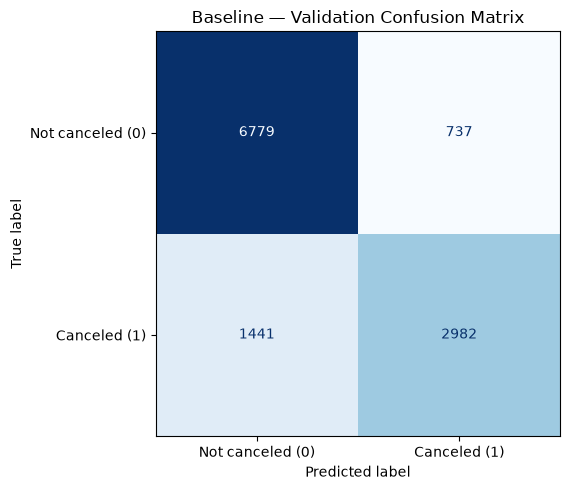

In [29]:
# Your code here; add additional cells as needed

val_cm = confusion_matrix(y_val, baseline_val_pred, labels=[0, 1])
tn, fp, fn, tp = val_cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=["Not canceled (0)", "Canceled (1)"],
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Baseline — Validation Confusion Matrix")
plt.tight_layout()


val_precision = precision_score(
    y_val, baseline_val_pred, pos_label=1, zero_division=0
)
val_recall = recall_score(
    y_val, baseline_val_pred, pos_label=1, zero_division=0
)
val_f1 = f1_score(
    y_val, baseline_val_pred, pos_label=1, zero_division=0
)

display(pd.DataFrame({
    "Precision (cancellation = 1)": [val_precision],
    "Recall (cancellation = 1)": [val_recall],
    "F1 (cancellation = 1)": [val_f1],
}, index=["Validation"]).round(4))

display(pd.DataFrame({
    "Outcome": [
        "True negative", "False positive", "False negative", "True positive"
    ],
    "Count": [tn, fp, fn, tp],
    "Meaning": [
        "Correctly predicted a booking would not be canceled.",
        "Predicted cancellation, but the booking was not canceled.",
        "Predicted no cancellation, but the booking was canceled.",
        "Correctly predicted a cancellation.",
    ],
}).set_index("Outcome"))

print(
    f"Precision: {val_precision:.1%} of predicted cancellations "
    "were actual cancellations."
)
print(
    f"Recall: the model identified {val_recall:.1%} "
    "of actual cancellations."
)

print(
    f"\nFalse positives ({fp:,}) are false cancellation alerts, which could "
    "lead to unnecessary interventions or overly aggressive overbooking."
)
print(
    f"False negatives ({fn:,}) are missed cancellations, which could "
    "leave hotels unprepared for empty rooms and lost revenue."
)

if fn > fp:
    print(f"\nFalse negatives occur more frequently, by {fn - fp:,} bookings.")
elif fp > fn:
    print(f"\nFalse positives occur more frequently, by {fp - fn:,} bookings.")
else:
    print("\nFalse positives and false negatives occur equally often.")

### Reflection 3.B — What the Baseline Misses

Based on your validation-set diagnostics:

1. Identify the **most important pattern or limitation** you observed in the baseline's predictions, citing at least one numerical result or plot.
2. Explain why this matters for the underlying prediction task.
3. Propose **one specific improvement or experiment** to investigate in Problems 4 or 5 that might address this limitation. Explain why you think it could help and what you expect to learn.

Write **a coherent response of approximately 100–150 words** in `a3b`.

In [30]:
error_pattern = (
    "The model misses more cancellations than it incorrectly flags."
    if fn > fp else
    "The model incorrectly flags more bookings than it misses cancellations."
    if fp > fn else
    "Both types of error occur equally often."
)


In [31]:
# Your answer here, NOT in the next cell

a3b = f"""
What stood out to me in the validation confusion matrix was the
{fn:,} missed cancellations compared with {fp:,} false cancellation
alerts. {error_pattern} Precision was {val_precision:.4f}, while recall
was {val_recall:.4f}. Looking at these separately helps me understand
what the model gets wrong, rather than relying only on F1.

These mistakes matter because missed cancellations can leave hotels
with empty rooms, while false alerts might lead to unnecessary
follow-ups or overbooking.

Booking far in advance might mean something different
depending on the deposit arrangement, which the baseline does not
explicitly capture. Keeping the model settings and threshold unchanged,
I would compare F1 and both error counts to see whether this feature
helps without simply trading one mistake for another.
"""

In [32]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
What stood out to me in the validation confusion matrix was the
1,441 missed cancellations compared with 737 false cancellation
alerts. The model misses more cancellations than it incorrectly flags. Precision was 0.8018, while recall
was 0.6742. Looking at these separately helps me understand
what the model gets wrong, rather than relying only on F1.

These mistakes matter because missed cancellations can leave hotels
with empty rooms, while false alerts might lead to unnecessary
follow-ups or overbooking.

Booking far in advance might mean something different
depending on the deposit arrangement, which the baseline does not
explicitly capture. Keeping the model settings and threshold unchanged,
I would compare F1 and both error counts to see whether this feature
helps without simply trading one mistake for another.



## Problem 4 — Feature Engineering Experiments [20 points]

In Problem 3, you established a baseline model using your original feature representation. In this problem, investigate whether changes to the predictor features improve validation performance.

Conduct **two distinct, hypothesis-driven feature-engineering experiments**. For each experiment, explain why the proposed change might help, implement it, and compare its results with the **unchanged baseline** from Problem 3.

- **Zillow:** Continue using `LinearRegression` and validation MAE (lower is better).
- **Hotel Booking:** Continue using `LogisticRegression` and validation F1 for cancellation class `1` (higher is better), with the default 0.5 classification threshold.

Keep the same training/validation partitions and baseline estimator settings. **Evaluate each change independently against the original baseline**, not cumulatively. Do not tune model hyperparameters or use the test set. Any transformations that learn parameters from the data must be fitted using training data only.

### Part A: Design and Evaluate Two Feature-Engineering Experiments [12 points]

Develop **two different feature-engineering changes** motivated by what you learned in Problems 1–3. Examples include a meaningful derived feature, a transformation of a skewed numerical predictor, or a different representation of an existing predictor. Choose changes appropriate to your dataset; do not simply remove predictors at random.

For each experiment:

1. State a specific **hypothesis**: what feature representation will you change, and why might it improve predictions?
2. Implement the change in a **reproducible, leakage-free workflow**. Apply the same feature definitions to training and validation data, fitting any learned transformations using training data only. Do not use validation performance to determine transformation parameters.
3. **Train a new model** using the same estimator type and hyperparameter settings as the original baseline, but with the modified feature representation. Generate training and validation predictions. Do not modify or overwrite `baseline_model`.
4. Report the **training and validation primary metric** for the experiment. Compare its validation score with the original baseline.

Present a compact results table with rows for **Baseline**, **Experiment 1**, and **Experiment 2**, including the feature change and both metric values. Keep code and plots necessary to understand the experiments visible in the notebook.

**Important:** Start each experiment from the original Problem 3 feature set and preprocessing design, making only that experiment's proposed change. Do not combine the two changes in this milestone.

**An experiment is not considered unsuccessful simply because validation performance fails to improve.** What matters is that you test a reasonable hypothesis, evaluate it correctly, and interpret the results.

In [34]:
# Your code here; add additional cells as needed.
# Implement and evaluate two independent feature-engineering experiments.
# Keep baseline_model unchanged and compare both experiments against it.
print(
    "Experiment 1 hypothesis: Lead time may affect cancellation differently "
    "depending on deposit type. Adding interaction features could capture "
    "relationships the baseline misses."
)
print(
    "\nExperiment 2 hypothesis: The effect of lead time may level off for "
    "bookings made far in advance. A log1p transformation could capture "
    "this nonlinear relationship better than the original representation."
)


# Experiment 1: Original features plus lead_time × deposit_type.
# Only this small interaction input matrix is made dense.
interaction_inputs = ColumnTransformer(
    transformers=[
        ("lead", clone(numerical_pipeline), ["lead_time"]),
        ("deposit", make_categorical_pipeline(), ["deposit_type"]),
    ],
    sparse_threshold=0.0,
)


def multiply_lead_by_deposit(values):
    """Multiply scaled lead time by each one-hot deposit category."""
    return values[:, :1] * values[:, 1:]


interaction_pipeline = Pipeline([
    ("inputs", interaction_inputs),
    ("products", FunctionTransformer(multiply_lead_by_deposit)),
])

experiment1_features = ColumnTransformer(
    transformers=[
        ("original", clone(preprocessor), X_train.columns.tolist()),
        (
            "interactions",
            interaction_pipeline,
            ["lead_time", "deposit_type"],
        ),
    ],
    sparse_threshold=1.0,
)

experiment1_model = Pipeline([
    ("preprocessor", experiment1_features),
    ("model", clone(baseline_model.named_steps["model"])),
])


# Experiment 2: Replace only lead_time with log1p(lead_time).
# This fixed transformation does not learn parameters.
def log_transform_lead_time(features):
    transformed = features.copy()
    if transformed["lead_time"].dropna().lt(0).any():
        raise ValueError("lead_time must be nonnegative for this experiment.")
    transformed["lead_time"] = np.log1p(transformed["lead_time"])
    return transformed


experiment2_model = Pipeline([
    ("log_lead", FunctionTransformer(log_transform_lead_time)),
    ("preprocessor", clone(preprocessor)),
    ("model", clone(baseline_model.named_steps["model"])),
])


def predict_cancellations(model, features):
    positive_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(features)[:, positive_index]
    return (probabilities >= 0.5).astype(int)


# Fit independently using the same original training partition.
# Learned preprocessing is fitted within each pipeline on training only.
experiment1_model.fit(X_train, y_train)
experiment2_model.fit(X_train, y_train)

experiment1_train_pred = predict_cancellations(experiment1_model, X_train)
experiment1_val_pred = predict_cancellations(experiment1_model, X_val)

experiment2_train_pred = predict_cancellations(experiment2_model, X_train)
experiment2_val_pred = predict_cancellations(experiment2_model, X_val)

# Retain predictions for later diagnostics.
feature_predictions = {
    "Baseline": (baseline_train_pred, baseline_val_pred),
    "Experiment 1": (experiment1_train_pred, experiment1_val_pred),
    "Experiment 2": (experiment2_train_pred, experiment2_val_pred),
}

feature_changes = {
    "Baseline": "Original representation",
    "Experiment 1": "Add lead_time × deposit_type interactions",
    "Experiment 2": "Replace lead_time with log1p(lead_time)",
}

feature_results = pd.DataFrame([
    {
        "Model": name,
        "Feature change": feature_changes[name],
        "Training F1": f1_score(
            y_train, train_pred, pos_label=1, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val, val_pred, pos_label=1, zero_division=0
        ),
    }
    for name, (train_pred, val_pred) in feature_predictions.items()
]).set_index("Model")

feature_results["Validation F1 change"] = (
    feature_results["Validation F1"]
    - feature_results.loc["Baseline", "Validation F1"]
)

display(feature_results.round(4))
print("Positive F1 changes indicate improvement over the baseline.")
print("Baseline unchanged; experiments independent")


Experiment 1 hypothesis: Lead time may affect cancellation differently depending on deposit type. Adding interaction features could capture relationships the baseline misses.

Experiment 2 hypothesis: The effect of lead time may level off for bookings made far in advance. A log1p transformation could capture this nonlinear relationship better than the original representation.


,Feature change,Training F1,Validation F1,Validation F1 change
Model,,,,
Baseline,Original representation,0.7351,0.7325,0.0000
Experiment 1,Add lead_time × deposit_type interactions,0.7351,0.7324,-0.0001
Experiment 2,Replace lead_time with log1p(lead_time),0.7537,0.7513,0.0188


Positive F1 changes indicate improvement over the baseline.
Baseline unchanged; experiments independent


### Reflection 4.A — Feature-Engineering Hypotheses and Results

For each of your two experiments:

1. Describe the feature change and **why you expected it to help**, connecting your hypothesis to characteristics of the dataset or the baseline's errors.
2. Report the **actual training and validation metric values** and quantify the change in validation performance relative to the original baseline.
3. Explain whether the result supports your hypothesis, what you learned from it, and identify one possible limitation of the experiment.

Write **a coherent response of approximately 150–200 words** in `a4a`.

In [35]:
base = feature_results.loc["Baseline"]
exp1 = feature_results.loc["Experiment 1"]
exp2 = feature_results.loc["Experiment 2"]

def describe_result(change):
    if change > 0:
        return "The improvement offers some support for this idea, but needs further checking."
    if change < 0:
        return "The lower score suggests this change did not help on this split."
    return "The unchanged score gives no evidence that this change helped."


In [36]:
# Your answer here, NOT in the next cell

a4a = f"""
My baseline had a training F1 of {base['Training F1']:.4f} and a validation
F1 of {base['Validation F1']:.4f}.

In Experiment 1, I added interactions between lead time and deposit type.
I thought booking far ahead might affect cancellations differently depending
on the deposit arrangement, a relationship the baseline could miss.
Training F1 was {exp1['Training F1']:.4f}, while validation F1 was
{exp1['Validation F1']:.4f}, changing by
{exp1['Validation F1 change']:+.4f} from baseline.
{describe_result(exp1['Validation F1 change'])}
I learned that allowing different lead-time effects does not automatically
make predictions better. One limitation is that less common deposit types
may have too few bookings for reliable estimates.

In Experiment 2, I replaced lead time with log1p(lead_time). My expectation
was that differences between short lead times might matter more than
differences between already-long lead times. Training F1 was
{exp2['Training F1']:.4f}, and validation F1 was {exp2['Validation F1']:.4f},
a change of {exp2['Validation F1 change']:+.4f} from baseline.
{describe_result(exp2['Validation F1 change'])}
This helped me assess whether changing the feature's shape was useful.
However, a logarithm assumes a particular relationship that may not fit
actual booking behavior. Both experiments used the same model settings
and threshold.
"""

In [37]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
My baseline had a training F1 of 0.7351 and a validation
F1 of 0.7325.

In Experiment 1, I added interactions between lead time and deposit type.
I thought booking far ahead might affect cancellations differently depending
on the deposit arrangement, a relationship the baseline could miss.
Training F1 was 0.7351, while validation F1 was
0.7324, changing by
-0.0001 from baseline.
The lower score suggests this change did not help on this split.
I learned that allowing different lead-time effects does not automatically
make predictions better. One limitation is that less common deposit types
may have too few bookings for reliable estimates.

In Experiment 2, I replaced lead time with log1p(lead_time). My expectation
was that differences between short lead times might matter more than
differences between already-long lead times. Training F1 was
0.7537, and validation F1 was 0.7513,
a change of +0.0188 from baseline.
The improvement offers some support for this idea, but needs furthe

### Part B: Compare the Experiments and Draw Conclusions [8 points]

Use your results from Part A to compare the two feature-engineering experiments and determine what they reveal about your selected prediction task.

1. **Compare all three feature representations**—the original baseline and both experiments. Identify which achieved the best validation performance and quantify its improvement or decline relative to the baseline.
2. Investigate **at least one difference beyond the primary validation metric**. For example, compare training–validation gaps, examine whether a particular error pattern improved, or investigate another relevant diagnostic measure. Support your analysis with a small table or plot.
3. Based on your findings, identify which feature changes, if any, you would consider carrying forward to the final project. Explain what additional experiments or evidence would help you decide.

**Do not combine the feature changes, tune hyperparameters, or evaluate on the test set.**

In [38]:
# Your code here; add additional cells as needed.
# Compare the baseline and both feature-engineering experiments.
comparison_4b = feature_results.copy()
comparison_4b["Training–validation gap"] = (
    comparison_4b["Training F1"] - comparison_4b["Validation F1"]
)

# Compare error types as well as overall F1.
for name, (_, predictions) in feature_predictions.items():
    _, false_positive, false_negative, _ = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    comparison_4b.loc[name, "Validation precision"] = precision_score(
        y_val, predictions, pos_label=1, zero_division=0
    )
    comparison_4b.loc[name, "Validation recall"] = recall_score(
        y_val, predictions, pos_label=1, zero_division=0
    )
    comparison_4b.loc[name, "False positives"] = false_positive
    comparison_4b.loc[name, "False negatives"] = false_negative

error_columns = ["False positives", "False negatives"]
comparison_4b[error_columns] = comparison_4b[error_columns].astype(int)

display(comparison_4b.round(4))

best_score = comparison_4b["Validation F1"].max()
best_names = comparison_4b.index[
    comparison_4b["Validation F1"].eq(best_score)
].tolist()
baseline_score = comparison_4b.loc["Baseline", "Validation F1"]

print(
    f"Best validation performance: {', '.join(best_names)}, "
    f"with F1 = {best_score:.4f}. "
    f"Change from baseline: {best_score - baseline_score:+.4f} F1."
)

for name in ["Experiment 1", "Experiment 2"]:
    row = comparison_4b.loc[name]
    fp_change = int(
        row["False positives"]
        - comparison_4b.loc["Baseline", "False positives"]
    )
    fn_change = int(
        row["False negatives"]
        - comparison_4b.loc["Baseline", "False negatives"]
    )
    print(
        f"\n{name}: validation F1 change = "
        f"{row['Validation F1 change']:+.4f}; "
        f"training–validation gap = {row['Training–validation gap']:+.4f}. "
        f"False-positive change = {fp_change:+d}; "
        f"false-negative change = {fn_change:+d}."
    )

print(
    "\nFalse negatives are missed cancellations; false positives are false "
    "cancellation alerts. These counts show whether an F1 improvement "
    "reduces both mistakes or trades one type for the other. "
    "Training–validation gaps provide context but do not prove overfitting."
)

promising = comparison_4b.loc[
    ["Experiment 1", "Experiment 2"]
].query("`Validation F1 change` > 0").index.tolist()

if promising:
    print(
        f"\nChanges worth further investigation: {', '.join(promising)}. "
        "Their higher validation F1 suggests that the original feature "
        "representation may miss useful patterns."
    )
else:
    print(
        "\nNeither feature change improved validation F1, so I would retain "
        "the original representation for now. These results do not support "
        "replacing it with either proposed change on this split."
    )

print(
    "Before carrying a change forward, I would check whether its advantage "
    "holds across training-only cross-validation and duplicate-aware or "
    "time-based validation. Practical value also depends on the costs of "
    "missed cancellations versus false alerts, not just F1. "
    "No features were combined, no hyperparameters were tuned, "
    "and the test set was not used."
)


,Feature change,Training F1,Validation F1,Validation F1 change,Training–validation gap,Validation precision,Validation recall,False positives,False negatives
Model,,,,,,,,,
Baseline,Original representation,0.7351,0.7325,0.0000,0.0026,0.8018,0.6742,737,1441
Experiment 1,Add lead_time × deposit_type interactions,0.7351,0.7324,-0.0001,0.0027,0.8022,0.6738,735,1443
Experiment 2,Replace lead_time with log1p(lead_time),0.7537,0.7513,0.0188,0.0024,0.8111,0.6998,721,1328


Best validation performance: Experiment 2, with F1 = 0.7513. Change from baseline: +0.0188 F1.

Experiment 1: validation F1 change = -0.0001; training–validation gap = +0.0027. False-positive change = -2; false-negative change = +2.

Experiment 2: validation F1 change = +0.0188; training–validation gap = +0.0024. False-positive change = -16; false-negative change = -113.

False negatives are missed cancellations; false positives are false cancellation alerts. These counts show whether an F1 improvement reduces both mistakes or trades one type for the other. Training–validation gaps provide context but do not prove overfitting.

Changes worth further investigation: Experiment 2. Their higher validation F1 suggests that the original feature representation may miss useful patterns.
Before carrying a change forward, I would check whether its advantage holds across training-only cross-validation and duplicate-aware or time-based validation. Practical value also depends on the costs of misse

### Reflection 4.B — What Did Feature Engineering Teach You?

1. Considering all three feature representations, what is your **overall conclusion** about the value of your feature-engineering experiments? Were the differences in validation performance large enough to be practically meaningful?
2. What did your additional diagnostic comparison reveal that the primary validation metric alone would not show?
3. Which feature changes, if any, would you consider carrying forward to the final project? Explain your reasoning and identify one important question that remains unanswered.

Support your conclusions with specific evidence from your results.

Write **a coherent response of approximately 100–150 words** in `a4b`.

In [39]:
b = comparison_4b.loc["Baseline"]
e1 = comparison_4b.loc["Experiment 1"]
e2 = comparison_4b.loc["Experiment 2"]

next_step = (
    f"I would explore {', '.join(promising)} further because it improved F1."
    if promising
    else "I would keep the original features, since neither change improved F1."
)

In [40]:
# Your answer here, NOT in the next cell

a4b = f"""
These experiments showed me that changing how a feature is represented
does not automatically make predictions better. Validation F1 was
{b['Validation F1']:.4f} for the baseline, {e1['Validation F1']:.4f} for
the lead-time/deposit interactions, and {e2['Validation F1']:.4f} for
log-transformed lead time. The best result came from
{', '.join(best_names)}, with a change of
{best_score - baseline_score:+.4f} from baseline. I would need more
evidence before treating this difference as practically meaningful.

Looking beyond F1 helped me understand the mistakes behind the scores.
The interaction experiment changed missed cancellations by
{int(e1['False negatives'] - b['False negatives']):+d} and false alerts by
{int(e1['False positives'] - b['False positives']):+d}. These errors have
different consequences for hotel planning, which F1 alone does not explain.

{next_step} My main unanswered question is whether these findings hold
for future bookings. Time-based validation within the training data
would help check that.
"""

In [41]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
These experiments showed me that changing how a feature is represented
does not automatically make predictions better. Validation F1 was
0.7325 for the baseline, 0.7324 for
the lead-time/deposit interactions, and 0.7513 for
log-transformed lead time. The best result came from
Experiment 2, with a change of
+0.0188 from baseline. I would need more
evidence before treating this difference as practically meaningful.

Looking beyond F1 helped me understand the mistakes behind the scores.
The interaction experiment changed missed cancellations by
+2 and false alerts by
-2. These errors have
different consequences for hotel planning, which F1 alone does not explain.

I would explore Experiment 2 further because it improved F1. My main unanswered question is whether these findings hold
for future bookings. Time-based validation within the training data
would help check that.



## Problem 5 — Compare Model Families [25 points]

In Problem 3, you established a linear or logistic regression baseline. In this problem, compare that baseline with a **tree ensemble** and a **feedforward neural network** to investigate how different model families perform on your selected prediction task.

Use the **original predictor representation from Problem 3**, not either feature-engineering experiment from Problem 4. Keep the same training/validation partitions and primary validation metric:

- **Zillow:** MAE (lower is better).
- **Hotel Booking:** F1 score for predicting canceled bookings (`is_canceled` = 1), with a classification threshold of 0.5.

Focus on a **fair initial comparison**, not an exhaustive search for the highest score. Fit all model parameters and learned preprocessing transformations using **training data only**. You may use validation data to evaluate and compare models, but **do not use the test set in this milestone**.

### Part A: Train and Compare Three Model Families [15 points]

Compare the fitted `baseline_model` from Problem 3 against **two new models**:

1. **Tree ensemble:** Train a `RandomForestRegressor` for Zillow or a `RandomForestClassifier` for Hotel Booking. Choose reasonable initial hyperparameter settings, including `random_state=42`. Do not perform a hyperparameter search.
2. **Feedforward neural network:** Build a modest Keras network with one or two hidden `Dense` layers and an appropriate output layer and loss function for your task. Set a random seed and use a fixed initial training configuration. Do not perform a hyperparameter search.
3. **Consistent evaluation:** Train both new models using the original Problem 3 predictor information and the same training partition. Fit all preprocessing transformations using training data only. You may adapt preprocessing to the needs of each model family (for example, numerical scaling or conversion to dense arrays), but **do not add or remove predictive features**.
4. **Compare results:** Report the training and validation primary metric for all three model families: the original baseline, the random forest, and the neural network. For Hotel Booking, use the same **0.5 classification threshold** for all models. Present the results in a compact, clearly labeled comparison table.

Retain the fitted models and preprocessing required to reproduce their predictions. You may include a neural-network learning curve if it helps explain the results.

**Choose initial model settings, train each new model once, and report the results without further tuning.** More systematic experimentation and optimization will take place in the final project. Do not use the modified feature representations from Problem 4 or evaluate on `X_test`.

In [43]:
# Your code here; add additional cells as needed.
# Compare baseline_model with a random forest and a feedforward neural network.
# Use the original Problem 3 features and the same train/validation split.
# Report training and validation metrics for all three models.


assert task == "classification" and a1_dataset == "Hotel Booking"

# Fixed initial configuration; no hyperparameter search.
rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )),
])
rf_model.fit(X_train, y_train)

rf_train_pred = predict_cancellations(rf_model, X_train)
rf_val_pred = predict_cancellations(rf_model, X_val)

# Independent copy of the original preprocessing workflow.
nn_preprocessor = clone(preprocessor)
nn_train_encoded = nn_preprocessor.fit_transform(X_train)
nn_val_encoded = nn_preprocessor.transform(X_val)

# Check memory requirements before converting to dense float32 arrays.
dense_bytes = (
    nn_train_encoded.shape[0] + nn_val_encoded.shape[0]
) * nn_train_encoded.shape[1] * np.dtype(np.float32).itemsize

print(f"Neural-network dense inputs: {dense_bytes / 1024**2:.1f} MiB")
if dense_bytes > 512 * 1024**2:
    raise MemoryError("Use batch-wise sparse-to-dense conversion for these inputs.")


def dense_float32(values):
    values = values.astype(np.float32)
    if hasattr(values, "toarray"):
        return values.toarray()
    return np.asarray(values)


nn_X_train = dense_float32(nn_train_encoded)
nn_X_val = dense_float32(nn_val_encoded)

# Two modest hidden layers; sigmoid output for cancellation probability.
tf.keras.utils.set_random_seed(42)
nn_model = Sequential([
    Input(shape=(nn_X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid"),
])
nn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
)

# Fixed training schedule; validation is used only for evaluation.
nn_history = nn_model.fit(
    nn_X_train,
    y_train.to_numpy(dtype=np.float32),
    epochs=20,
    batch_size=256,
    shuffle=True,
    verbose=2,
)

nn_train_pred = (
    nn_model.predict(nn_X_train, batch_size=256, verbose=0).ravel() >= 0.5
).astype(int)
nn_val_pred = (
    nn_model.predict(nn_X_val, batch_size=256, verbose=0).ravel() >= 0.5
).astype(int)

# Reuse the unchanged baseline predictions from Problem 3.
family_predictions = {
    "Logistic regression": (baseline_train_pred, baseline_val_pred),
    "Random forest": (rf_train_pred, rf_val_pred),
    "Neural network": (nn_train_pred, nn_val_pred),
}

family_results = pd.DataFrame([
    {
        "Model": name,
        "Training F1": f1_score(
            y_train, train_pred, pos_label=1, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val, val_pred, pos_label=1, zero_division=0
        ),
    }
    for name, (train_pred, val_pred) in family_predictions.items()
]).set_index("Model")

family_results["Training–validation gap"] = (
    family_results["Training F1"] - family_results["Validation F1"]
)
family_results["Validation F1 change"] = (
    family_results["Validation F1"]
    - family_results.loc["Logistic regression", "Validation F1"]
)

display(family_results.round(4))
print("All models evaluated at threshold 0.5.")
print("Retained: baseline_model, rf_model, nn_model, nn_preprocessor, nn_history.")

Neural-network dense inputs: 38.9 MiB
Epoch 1/20
374/374 - 1s - 1ms/step - loss: 0.3933
Epoch 2/20
374/374 - 0s - 338us/step - loss: 0.3190
Epoch 3/20
374/374 - 0s - 334us/step - loss: 0.3039
Epoch 4/20
374/374 - 0s - 403us/step - loss: 0.2963
Epoch 5/20
374/374 - 0s - 336us/step - loss: 0.2905
Epoch 6/20
374/374 - 0s - 333us/step - loss: 0.2867
Epoch 7/20
374/374 - 0s - 335us/step - loss: 0.2830
Epoch 8/20
374/374 - 0s - 334us/step - loss: 0.2799
Epoch 9/20
374/374 - 0s - 333us/step - loss: 0.2775
Epoch 10/20
374/374 - 0s - 333us/step - loss: 0.2752
Epoch 11/20
374/374 - 0s - 333us/step - loss: 0.2731
Epoch 12/20
374/374 - 0s - 341us/step - loss: 0.2713
Epoch 13/20
374/374 - 0s - 333us/step - loss: 0.2697
Epoch 14/20
374/374 - 0s - 335us/step - loss: 0.2682
Epoch 15/20
374/374 - 0s - 335us/step - loss: 0.2669
Epoch 16/20
374/374 - 0s - 334us/step - loss: 0.2656
Epoch 17/20
374/374 - 0s - 333us/step - loss: 0.2643
Epoch 18/20
374/374 - 0s - 332us/step - loss: 0.2631
Epoch 19/20
374/374

,Training F1,Validation F1,Training–validation gap,Validation F1 change
Model,,,,
Logistic regression,0.7351,0.7325,0.0026,0.0000
Random forest,0.8108,0.7987,0.0121,0.0662
Neural network,0.8399,0.8234,0.0165,0.0909


All models evaluated at threshold 0.5.
Retained: baseline_model, rf_model, nn_model, nn_preprocessor, nn_history.


### Reflection 5.A — Comparing Model Families

1. Compare the training and validation results for all three model families, citing **specific metric values** from your results table. Which model performed best on the validation set, and by how much relative to the baseline?
2. What evidence, if any, suggests underfitting or overfitting? Explain why **better training performance does not necessarily mean better generalization**.
3. Discuss one practical tradeoff among the model families, such as interpretability, training complexity, or sensitivity to preprocessing.

Base your discussion on your own results. Write **a coherent response of approximately 150–200 words** in `a5a`.

In [44]:
lr = family_results.loc["Logistic regression"]
rf = family_results.loc["Random forest"]
nn = family_results.loc["Neural network"]

best_f1 = family_results["Validation F1"].max()
best_models = ", ".join(
    family_results.index[family_results["Validation F1"].eq(best_f1)]
)
improvement = best_f1 - lr["Validation F1"]


In [45]:
# Your answer here, NOT in the next cell

a5a = f"""
My logistic regression baseline scored {lr['Training F1']:.4f} on training
data and {lr['Validation F1']:.4f} on validation data. The random forest
scored {rf['Training F1']:.4f} and {rf['Validation F1']:.4f}, while the
neural network scored {nn['Training F1']:.4f} and
{nn['Validation F1']:.4f}, respectively. The best validation result came
from {best_models}, with F1 of {best_f1:.4f}, a gain of
{improvement:.4f} over the baseline.

Looking beyond the highest score, I compared the training–validation
gaps: {lr['Training–validation gap']:+.4f} for logistic regression,
{rf['Training–validation gap']:+.4f} for the forest, and
{nn['Training–validation gap']:+.4f} for the network. A larger positive
gap raises more concern about overfitting. However, these results alone
cannot confirm overfitting or underfitting. A model can perform well on
training bookings by picking up patterns that do not hold for new
reservations, so better training F1 does not necessarily mean better
generalization.

One practical tradeoff is how easily the predictions can be explained.
Logistic regression makes it easier to discuss individual feature
effects. Forests and neural networks can capture more complicated
relationships, but their predictions are harder to explain. The network
also needs more attention to scaling and training settings. I would
check whether the validation advantage holds for future bookings before
choosing a final model.

"""

In [46]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5a = {a5a}")

a5a = 
My logistic regression baseline scored 0.7351 on training
data and 0.7325 on validation data. The random forest
scored 0.8108 and 0.7987, while the
neural network scored 0.8399 and
0.8234, respectively. The best validation result came
from Neural network, with F1 of 0.8234, a gain of
0.0909 over the baseline.

Looking beyond the highest score, I compared the training–validation
gaps: +0.0026 for logistic regression,
+0.0121 for the forest, and
+0.0165 for the network. A larger positive
gap raises more concern about overfitting. However, these results alone
cannot confirm overfitting or underfitting. A model can perform well on
training bookings by picking up patterns that do not hold for new
reservations, so better training F1 does not necessarily mean better
generalization.

One practical tradeoff is how easily the predictions can be explained.
Logistic regression makes it easier to discuss individual feature
effects. Forests and neural networks can capture more complicated
rel

### Part B: Investigate Model Complexity and Draw Conclusions [10 points]

Choose **one** of the two new model families (random forest or neural network) and conduct **one controlled experiment** to investigate model complexity.

1. State a hypothesis about how **one complexity-related setting** might influence training and validation performance. Examples include `max_depth` for the random forest or the number of units in a neural-network hidden layer.
2. Starting with the model configuration used in Part A, train **one additional version** of the selected model, changing **only the chosen complexity setting**. Keep the same features, data partitions, evaluation metric, and other model settings. Fit preprocessing transformations using training data only, and use `random_state=42` or the same Keras seed where applicable.
3. Compare the **original and modified versions** using both training and validation performance. Display a compact table or plot showing the effect of the change.
4. Based on all your results from Problem 5, identify which model family appears most promising for further investigation in the **final project**. Explain your choice and propose one additional experiment or question worth pursuing during the final three weeks.

Your goal is to understand the **effect of a controlled change**, not necessarily to improve performance. **Do not perform grid search, evaluate on the test set, or claim that a single validation result establishes which model will generalize best.**

In [47]:
# Your code here; add additional cells as needed.
# Change one complexity-related setting in either the random forest or neural network.
# Compare its training and validation performance with the original version.
print(
    "Hypothesis: Removing the depth limit will let the forest capture more "
    "detailed booking patterns, likely improving training F1. Validation F1 "
    "may improve if the original forest underfits, or decline if the extra "
    "complexity fits training-specific patterns."
)

# Clone the Part A pipeline; change only the depth limit.
rf_complex_model = clone(rf_model)
rf_complex_model.set_params(model__max_depth=None)

# Confirm that all other estimator settings remain unchanged.
original_params = rf_model.named_steps["model"].get_params()
modified_params = rf_complex_model.named_steps["model"].get_params()
changed_settings = [
    key for key in original_params
    if original_params[key] != modified_params[key]
]
assert changed_settings == ["max_depth"]

# Fit preprocessing and the additional forest on training data only.
rf_complex_model.fit(X_train, y_train)

rf_complex_train_pred = predict_cancellations(rf_complex_model, X_train)
rf_complex_val_pred = predict_cancellations(rf_complex_model, X_val)

complexity_results = pd.DataFrame([
    {
        "Version": "Original forest",
        "max_depth": "15",
        "Training F1": family_results.loc["Random forest", "Training F1"],
        "Validation F1": family_results.loc["Random forest", "Validation F1"],
    },
    {
        "Version": "Unlimited-depth forest",
        "max_depth": "None",
        "Training F1": f1_score(
            y_train, rf_complex_train_pred, pos_label=1, zero_division=0
        ),
        "Validation F1": f1_score(
            y_val, rf_complex_val_pred, pos_label=1, zero_division=0
        ),
    },
]).set_index("Version")

complexity_results["Training–validation gap"] = (
    complexity_results["Training F1"] - complexity_results["Validation F1"]
)
display(complexity_results.round(4))

changes = (
    complexity_results.loc[
        "Unlimited-depth forest", ["Training F1", "Validation F1"]
    ]
    - complexity_results.loc[
        "Original forest", ["Training F1", "Validation F1"]
    ]
)
print(f"Training F1 change: {changes['Training F1']:+.4f}")
print(f"Validation F1 change: {changes['Validation F1']:+.4f}")

# Compare all Problem 5 configurations without retraining earlier models.
all_5_results = family_results[["Training F1", "Validation F1"]].copy()
all_5_results.loc["Random forest (unlimited depth)"] = (
    complexity_results.loc[
        "Unlimited-depth forest", ["Training F1", "Validation F1"]
    ]
)

top_score = all_5_results["Validation F1"].max()
top_names = all_5_results.index[
    all_5_results["Validation F1"].eq(top_score)
].tolist()

display(all_5_results.round(4))
print(
    f"Most promising configuration(s) on this split: {', '.join(top_names)} "
    f"(validation F1 = {top_score:.4f}). "
    "This makes the associated model family or families worth investigating, "
    "but does not establish which will generalize best."
)
print(
    "Next experiment: compare the promising approaches using time-based "
    "validation within the training partition to check performance on later "
    "bookings. Duplicate overlap and changing booking behavior remain concerns."
)
print("All predictions use threshold 0.5. The test set was not used.")


Hypothesis: Removing the depth limit will let the forest capture more detailed booking patterns, likely improving training F1. Validation F1 may improve if the original forest underfits, or decline if the extra complexity fits training-specific patterns.


,max_depth,Training F1,Validation F1,Training–validation gap
Version,,,,
Original forest,15,0.8108,0.7987,0.0121
Unlimited-depth forest,None,0.9327,0.8419,0.0907


Training F1 change: +0.1219
Validation F1 change: +0.0432


,Training F1,Validation F1
Model,,
Logistic regression,0.7351,0.7325
Random forest,0.8108,0.7987
Neural network,0.8399,0.8234
Random forest (unlimited depth),0.9327,0.8419


Most promising configuration(s) on this split: Random forest (unlimited depth) (validation F1 = 0.8419). This makes the associated model family or families worth investigating, but does not establish which will generalize best.
Next experiment: compare the promising approaches using time-based validation within the training partition to check performance on later bookings. Duplicate overlap and changing booking behavior remain concerns.
All predictions use threshold 0.5. The test set was not used.


### Reflection 5.B — Complexity and Next Steps

1. What complexity setting did you change, and why did you expect it to affect model behavior?
2. Report the **actual training and validation results** before and after the change. What do these results suggest about the relationship between model complexity, overfitting or underfitting, and generalization?
3. Based on the model-family comparisons and this experiment, which approach would you investigate further in the final project? Explain your choice and identify one important uncertainty that remains.

Support your conclusions with specific results. Write **a coherent response of approximately 125–175 words** in `a5b`.

In [48]:
original = complexity_results.loc["Original forest"]
modified = complexity_results.loc["Unlimited-depth forest"]

if changes["Validation F1"] > 0:
    complexity_takeaway = (
        "The validation improvement suggests the depth limit may have "
        "restricted useful patterns, although it does not prove underfitting."
    )
elif changes["Training F1"] > 0 and changes["Validation F1"] < 0:
    complexity_takeaway = (
        "Better training F1 alongside lower validation F1 is consistent "
        "with increased overfitting."
    )
else:
    complexity_takeaway = (
        "The extra complexity did not improve validation F1, so deeper "
        "trees were not more useful on this split."
    )

In [49]:
# Your answer here, NOT in the next cell

a5b = f"""
I changed the random forest's max_depth from 15 to None, keeping everything
else unchanged. I expected deeper trees to capture more detailed booking
patterns, but also risk learning details specific to the training data.

The original forest scored {original['Training F1']:.4f} on training data
and {original['Validation F1']:.4f} on validation data. Without the depth
limit, these scores were {modified['Training F1']:.4f} and
{modified['Validation F1']:.4f}, respectively. Validation F1 changed by
{changes['Validation F1']:+.4f}. {complexity_takeaway}
Better training performance alone does not establish better generalization.

Across all configurations, I would investigate
{', '.join(top_names)} further because it achieved the highest validation
F1, {top_score:.4f}. This is a starting point, not a final model choice.
My main uncertainty is whether this advantage holds for future bookings,
especially as booking behavior changes. Next, I would compare the
approaches using time-based validation within the training partition,
while keeping the test set untouched.

"""

In [50]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5b = {a5b}")

a5b = 
I changed the random forest's max_depth from 15 to None, keeping everything
else unchanged. I expected deeper trees to capture more detailed booking
patterns, but also risk learning details specific to the training data.

The original forest scored 0.8108 on training data
and 0.7987 on validation data. Without the depth
limit, these scores were 0.9327 and
0.8419, respectively. Validation F1 changed by
+0.0432. The validation improvement suggests the depth limit may have restricted useful patterns, although it does not prove underfitting.
Better training performance alone does not establish better generalization.

Across all configurations, I would investigate
Random forest (unlimited depth) further because it achieved the highest validation
F1, 0.8419. This is a starting point, not a final model choice.
My main uncertainty is whether this advantage holds for future bookings,
especially as booking behavior changes. Next, I would compare the
approaches using time-based validation 

## Submission Checklist

Before submitting your milestone notebook to Gradescope, verify the following:

-  **All five problems are complete**, including the required code, tables, plots, and reflections.
-  You explored both datasets in Problem 1 and used your selected dataset consistently throughout Problems 2–5.
-  Your training, validation, and test partitions are correctly defined, and all learned preprocessing transformations were fitted using training data only.
-  You evaluated the baseline, feature-engineering experiments, and three model families using the required validation metric.
-  **You did not evaluate any model on the test set.** The test set is reserved for the final project.
-  All reflection variables (`a1a`, `a1b`, `a2a`–`a2d`, `a3a`, `a3b`, `a4a`, `a4b`, `a5a`, `a5b`) contain your own substantive answers.
-  You ran all the **Graded Answer** cells without modifying them.
-  You restarted the kernel and ran the entire notebook from beginning to end without errors.
-  All relevant code output, tables, and plots are visible in the submitted notebook.

**Submit your completed `.ipynb` file to Gradescope.** Do not submit the datasets or any additional files.

**Due: Sunday, November 15th at 11:59 PM**, with a 2-hour and 1-minute grace period. 

**No late submissions -- We have to start grading immediately!**